# GRU collision monitor on schema-v2 logs: a simple case study

**Question:** a small GRU reads the last **3 s** of what TF++ outputs and decides whether a collision follows in the next **3 s**. Does it do better when it also sees **TF++'s own predicted boxes** of other actors?

The earlier pilot ([gru_collision_monitor.ipynb](gru_collision_monitor.ipynb)) used v1 logs, which have no boxes. This notebook repeats the idea on the v2 logs in `results/bench2drive_v2/`, with the same labels, folds and metrics as [prediction_baselines.ipynb](prediction_baselines.ipynb) so the numbers are comparable.

This is a case study to get an idea, not a full study: two GRUs, two simple baselines, one random seed, no tuning and no ablations.

| Section | What it does |
|---|---|
| 1. Data | 3 s windows of TF++ outputs, label = collision within 3 s, with and without box features |
| 2. Model | One small GRU (1 layer, 64 units) |
| 3. Training | 5-fold cross-validation grouped by route, early stopping on held-out routes |
| 4. Evaluation | AUROC/AUPRC and "collisions warned ≥ 1 s / ≥ 2 s ahead" at a fixed alarm budget |
| 5. Findings | What the numbers say |

In [1]:
import sys, csv, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.metrics import average_precision_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit

REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(REPO / "src"))
import ew_analysis as ew
import fg_analysis as fg

RESULTS = REPO / "results" / "bench2drive_v2"
OUT = RESULTS / "gru_v2"
OUT.mkdir(parents=True, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
H = 60                       # 3 s of history at 20 Hz
BUDGET = 0.02                # main operating point: 2% of normal driving time in alarm
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})
print("device:", DEVICE)

device: cuda


## 1. Data

**Samples and labels.** Every 20 Hz step of every route is one sample. The input is the 60 steps (3 s) up to and including that step; the label is 1 if a counted collision happens within the next 3 s. The labels, exclusions (first 2 s of a route, the 3 s after any contact) and collision list come unchanged from notebook 1 (`ew_analysis.build_dataset`), so they match notebooks 6 and 7.

**Features per step.** Two versions of the input:

| Version | Features (all produced or observed by TF++; ground truth is never an input) |
|---|---|
| **No boxes** (like the v1 pilot) | ego speed, target speed, speed gap, speed-head entropy and margin, brake, \|steer\|, path curvature, path end offset |
| **+ boxes** | the above, plus the **nearest 2 TF++ boxes** (x, y in the ego frame and a "present" flag), plus **box geometry** against TF++'s planned path: time-to-collision risk, minimum clearance, time gap, conflict flag, gap and closing speed to the box ahead, number of boxes, TF++'s own "box in front" flag |

**Combining different units (m, m/s, probabilities).** Every step becomes one fixed-length vector. Box positions are relative to the ego car, so "12 m ahead" means the same thing everywhere. Each feature is then standardised with the mean and standard deviation of the **training routes only**, so all features end up on a similar scale. An empty box slot is set to 0 after scaling, and its "present" flag (0/1, not scaled) tells the GRU the slot is empty.

In [2]:
# labels and collision events: identical to notebooks 6 and 7
routes, ckpts, EW = ew.build_cache(RESULTS, REPO / "carla_garage/leaderboard/data/bench2drive220.xml",
                                   RESULTS / "early_warning" / "cache.pkl")
events = ew.event_table(routes, ckpts, EW)
F, M, ev_index, untimed = ew.build_dataset(routes, ckpts, EW, events)
EIDS = sorted({e["eid"] for e in ev_index})
G = M["route"]
print(f"routes {len(np.unique(G))} | samples {len(M['y']):,} | positive samples {M['y'].sum():,} "
      f"({M['y'].mean():.1%}) | collisions {len(EIDS)}")

routes 214 | samples 147,531 | positive samples 3,042 (2.1%) | collisions 60


In [3]:
# raw positions of the 2 nearest TF++ boxes per step (one pass over the JSONL logs, cached)
import json
K = 2
box_cache = OUT / "nearest_boxes.npz"
if box_cache.exists():
    NB = dict(np.load(box_cache))
else:
    t0 = time.time()
    NB = {}
    for rid in EW:
        rows = [json.loads(l) for l in open(ew.pick_log(RESULTS / "logs" / rid))]
        a = np.zeros((len(rows), 3 * K), np.float32)
        for i, r in enumerate(rows):
            b = ew._boxes(r)                                   # vehicles, pedestrians, bikes (as in notebook 1)
            if len(b):
                b = b[np.argsort(np.hypot(b[:, 0], b[:, 1]))[:K]]
                for k in range(len(b)):
                    a[i, 3 * k: 3 * k + 3] = (b[k, 0], b[k, 1], 1.0)
        assert len(rows) == EW[rid]["n"]
        NB[rid] = a
    np.savez_compressed(box_cache, **NB)
    print(f"parsed {len(NB)} logs in {time.time() - t0:.0f} s")
print("box slots per step:", NB[next(iter(NB))].shape[1])

box slots per step: 6


In [4]:
BASE = ["ego_speed", "target_speed", "speed_gap", "speed_entropy", "speed_margin", "brake", "steer_abs",
        "path_curvature", "path_end_lat_abs"]
BOX_XY = [f"box{k + 1}_{c}" for k in range(K) for c in ("x", "y", "present")]
GEOM = ["risk_plan", "clear_plan", "pet_plan", "conflict_plan", "corr_dist", "corr_close", "n_boxes", "bb_in_front"]
FEATS = {"GRU: no boxes": BASE, "GRU: + boxes": BASE + BOX_XY + GEOM}
BINARY = {c for c in BOX_XY if c.endswith("present")} | {"conflict_plan", "bb_in_front"}

# one long [all steps of all routes, features] table; a window is 60 consecutive rows of one route
ALL_COLS = BASE + BOX_XY + GEOM
rid_list = sorted(EW, key=int)
offset, parts = {}, []
start = 0
for rid in rid_list:
    f = ew.step_features(EW[rid])
    cols = {c: f[c] for c in BASE + GEOM}
    cols.update({c: NB[rid][:, j] for j, c in enumerate(BOX_XY)})
    parts.append(np.stack([cols[c] for c in ALL_COLS], 1).astype(np.float32))
    offset[int(rid)] = start
    start += EW[rid]["n"]
TABLE = np.concatenate(parts)
route_len = {int(r): EW[r]["n"] for r in rid_list}

# window index for every sample: rows (step-59 .. step) of its route, padded with the route's first step
lags = np.arange(H - 1, -1, -1)
WIN = np.stack([offset[r] + np.clip(s - lags, 0, None) for r, s in zip(M["route"], M["step"])])
print("feature table", TABLE.shape, "| windows", WIN.shape)

# what one input looks like: 1 s before a collision (raw units, last 3 steps of the window)
e = ev_index[0]
i = np.where((M["route"] == int(e["route"])) & (M["step"] == e["step"] - 20))[0][0]
show = ["ego_speed", "speed_entropy", "box1_x", "box1_y", "box1_present", "clear_plan", "risk_plan"]
print(f"\nroute {e['route']}, 1 s before hitting {e['other_type']} (raw values, last 3 of 60 steps):")
print("  " + "".join(f"{c:>14s}" for c in show))
for row in WIN[i, -3:]:
    print("  " + "".join(f"{TABLE[row, ALL_COLS.index(c)]:14.2f}" for c in show))

feature table (175264, 23) | windows (147531, 60)

route 1790, 1 s before hitting vehicle.ford.mustang (raw values, last 3 of 60 steps):
       ego_speed speed_entropy        box1_x        box1_y  box1_present    clear_plan     risk_plan
            8.83          0.31          3.21          4.67          1.00         -0.54          1.90
            9.23          0.42          2.84          4.40          1.00         -0.70          1.60
            9.60          0.36          2.54          4.44          1.00         -0.17          1.00


## 2. Model

A deliberately small GRU: one layer with 64 hidden units reads the 60 steps, and a linear layer turns the last hidden state into one collision score. The same architecture is used for both inputs; only the number of input features changes (9 without boxes, 23 with boxes).

Two simple, non-temporal references from notebook 6 are included so the GRU has something to beat:
- **LR: speed only**: logistic regression on ego speed (the baseline that matched most of the signal in earlier work).
- **LR: current-frame geometry**: logistic regression on the box-geometry features at the current step only (notebook 6's best simple monitor).

In [5]:
class GRUMonitor(nn.Module):
    def __init__(self, n_in, hidden=64):
        super().__init__()
        self.gru = nn.GRU(n_in, hidden, batch_first=True)
        self.drop = nn.Dropout(0.2)
        self.head = nn.Linear(hidden, 1)

    def forward(self, x):                      # x: [batch, 60, features]
        _, h = self.gru(x)
        return self.head(self.drop(h[-1])).squeeze(-1)

for name, cols in FEATS.items():
    print(f"{name:15s} inputs {len(cols):2d} | parameters {sum(p.numel() for p in GRUMonitor(len(cols)).parameters()):,}")

GRU: no boxes   inputs  9 | parameters 14,465
GRU: + boxes    inputs 23 | parameters 17,153


## 3. Training

- **Folds:** 5-fold cross-validation grouped by route (the same folds as notebook 6). Every route, and so every collision, is in the test fold exactly once, and no route is in both training and test.
- **Inside each fold:** 20% of the training routes are held out as validation. The GRU trains on the rest with class-weighted binary cross-entropy (collisions are ~2% of samples), Adam, batch 512, and stops early when validation AUPRC on moving steps has not improved for 4 epochs.
- **Alarm threshold:** chosen on the validation routes only, so that 2% of normal driving time is in alarm. The test routes are never used to pick anything.
- One random seed. The logistic-regression references use notebook 6's routine (`fg.cross_validate`).

In [6]:
def standardise(X_rows, cols, fit_rows):
    mu, sd = X_rows[fit_rows].mean(0), X_rows[fit_rows].std(0) + 1e-6
    for j, c in enumerate(cols):
        if c in BINARY:
            mu[j], sd[j] = 0.0, 1.0
    Z = np.clip((X_rows - mu) / sd, -5, 5)
    for k in range(K):                       # empty box slot -> 0 after scaling
        if f"box{k + 1}_present" in cols:
            p = Z[:, cols.index(f"box{k + 1}_present")]
            for c in ("x", "y"):
                Z[:, cols.index(f"box{k + 1}_{c}")] *= p
    return Z.astype(np.float32)


def predict(model, T, idx, bs=4096):
    model.eval()
    out = []
    with torch.no_grad():
        for s in range(0, len(idx), bs):
            w = torch.as_tensor(WIN[idx[s:s + bs]], device=DEVICE)
            out.append(model(T[w]).float().cpu().numpy())
    return np.concatenate(out) if out else np.zeros(0)


def train_fold(cols, tr, va, seed, max_epochs=25, patience=4, bs=512):
    torch.manual_seed(seed); np.random.seed(seed)
    fit_routes = np.isin(np.repeat(np.array([int(r) for r in rid_list]), [route_len[int(r)] for r in rid_list]),
                         np.unique(M["route"][tr]))
    T = torch.as_tensor(standardise(TABLE[:, [ALL_COLS.index(c) for c in cols]], cols, fit_routes), device=DEVICE)
    y = torch.as_tensor(M["y"], dtype=torch.float32, device=DEVICE)
    model = GRUMonitor(len(cols)).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    pos_w = torch.tensor((M["y"][tr] == 0).sum() / max(M["y"][tr].sum(), 1), device=DEVICE)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_w)
    va_mv = va[M["moving"][va]]
    best, best_state, wait, history = -1.0, None, 0, []
    for epoch in range(max_epochs):
        model.train()
        perm = np.random.permutation(tr)
        total = 0.0
        for s in range(0, len(perm), bs):
            b = perm[s:s + bs]
            w = torch.as_tensor(WIN[b], device=DEVICE)
            loss = loss_fn(model(T[w]), y[torch.as_tensor(b, device=DEVICE)])
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * len(b)
        ap = average_precision_score(M["y"][va_mv], predict(model, T, va_mv))
        history.append((total / len(perm), ap))
        if ap > best:
            best, best_state, wait = ap, {k: v.detach().clone() for k, v in model.state_dict().items()}, 0
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    return model, T, history, best


S, CURVES = {}, {}
folds = list(GroupKFold(n_splits=5).split(M["y"], M["y"], G))
for name, cols in FEATS.items():
    score, thr = np.zeros(len(M["y"])), np.zeros(len(M["y"]))
    CURVES[name] = []
    t0 = time.time()
    for fo, (tr_all, te) in enumerate(folds):
        tr_i, va_i = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=fo).split(tr_all, groups=G[tr_all]))
        tr, va = tr_all[tr_i], tr_all[va_i]
        model, T, hist, best = train_fold(cols, tr, va, seed=fo)
        CURVES[name].append(hist)
        val_score = predict(model, T, va)
        thr[te] = np.quantile(val_score[M["y"][va] == 0], 1 - BUDGET)
        score[te] = predict(model, T, te)
        print(f"{name:15s} fold {fo}: {len(hist):2d} epochs, best val AUPRC {best:.3f}, "
              f"test collisions {len(set(M['eid'][te][M['y'][te] == 1]))}")
    S[name] = (score, {BUDGET: thr})
    print(f"  ({time.time() - t0:.0f} s)")

for name, cols in {"LR: speed only": fg.SPEED, "LR: current-frame geometry": fg.GEOMETRY}.items():
    score, thr = fg.cross_validate(fg.design(F, cols), M["y"], G, budgets=(BUDGET,))
    S[name] = (score, thr)
print("done:", list(S))

GRU: no boxes   fold 0:  6 epochs, best val AUPRC 0.214, test collisions 13


GRU: no boxes   fold 1:  9 epochs, best val AUPRC 0.193, test collisions 14


GRU: no boxes   fold 2:  8 epochs, best val AUPRC 0.314, test collisions 12


GRU: no boxes   fold 3:  5 epochs, best val AUPRC 0.100, test collisions 6


GRU: no boxes   fold 4: 11 epochs, best val AUPRC 0.271, test collisions 15
  (16 s)


GRU: + boxes    fold 0:  6 epochs, best val AUPRC 0.270, test collisions 13


GRU: + boxes    fold 1:  7 epochs, best val AUPRC 0.302, test collisions 14


GRU: + boxes    fold 2:  6 epochs, best val AUPRC 0.445, test collisions 12


GRU: + boxes    fold 3: 14 epochs, best val AUPRC 0.648, test collisions 6


GRU: + boxes    fold 4: 10 epochs, best val AUPRC 0.395, test collisions 15
  (17 s)


done: ['GRU: no boxes', 'GRU: + boxes', 'LR: speed only', 'LR: current-frame geometry']


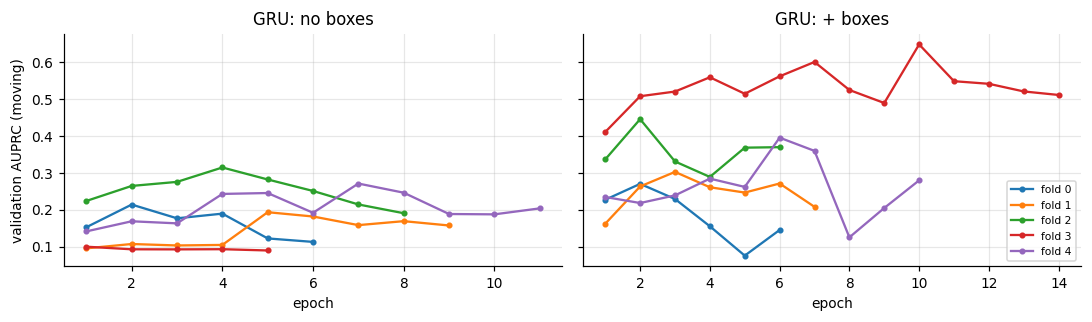

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
for ax, (name, hists) in zip(axes, CURVES.items()):
    for fo, h in enumerate(hists):
        ax.plot(range(1, len(h) + 1), [a for _, a in h], marker="o", ms=3, label=f"fold {fo}")
    ax.set_title(name); ax.set_xlabel("epoch")
axes[0].set_ylabel("validation AUPRC (moving)"); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(OUT / "training_curves.png", bbox_inches="tight"); plt.show()

## 4. Evaluation

All numbers are on **test routes** (out-of-fold), pooled over the 5 folds, with 95% intervals from resampling routes.

- **AUROC / AUPRC (moving):** how well the score ranks danger, on steps where the ego moves faster than 2 m/s (stopped steps are trivially safe and would inflate the numbers). AUPRC's chance level is the share of positive steps.
- **Warned ≥ 1 s / ≥ 2 s:** share of the 60 collisions with an alarm at least 1 s (or 2 s) before impact, when the threshold allows **2% of normal driving time in alarm** (chosen on validation routes).
- **Median lead:** how early the first alarm comes before impact (0 if never warned).

In [8]:
from IPython.display import Markdown, display

def table(rows):
    cols = list(rows[0])
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    lines += ["| " + " | ".join(str(r[c]) for c in cols) + " |" for r in rows]
    display(Markdown("\n".join(lines)))

ci = lambda v, c, pct=False: (f"{100 * v:.0f}% [{100 * c[0]:.0f}, {100 * c[1]:.0f}]" if pct
                              else f"{v:.3f} [{c[0]:.3f}, {c[1]:.3f}]")
R, rows = {}, []
for name, (score, thr) in S.items():
    auc, ap = fg.ranking(score, M)
    a = fg.alarm_metrics(score, thr[BUDGET], M, EIDS)
    c = fg.bootstrap(score, thr, M, EIDS, budgets=(BUDGET,))
    R[name] = a
    rows.append({"monitor": name, "AUROC (moving)": ci(auc, c["auroc"]), "AUPRC (moving)": ci(ap, c["auprc"]),
                 "warned ≥ 1 s": ci(a["recall_1s"], c[f"recall_1s@{BUDGET}"], True),
                 "warned ≥ 2 s": ci(a["recall_2s"], c[f"recall_2s@{BUDGET}"], True),
                 "median lead (s)": f"{a['median_lead']:.2f}",
                 "time in alarm (test)": f"{100 * a['alarm_time']:.1f}%"})
display(Markdown(f"**Results at a {BUDGET:.0%} alarm budget.** Chance AUPRC (moving) = "
                 f"{M['y'][M['moving']].mean():.3f}; collisions = {len(EIDS)}."))
table(rows)
with open(OUT / "results.csv", "w", newline="") as fh:
    w = csv.DictWriter(fh, fieldnames=list(rows[0])); w.writeheader(); w.writerows(rows)

**Results at a 2% alarm budget.** Chance AUPRC (moving) = 0.057; collisions = 60.

| monitor | AUROC (moving) | AUPRC (moving) | warned ≥ 1 s | warned ≥ 2 s | median lead (s) | time in alarm (test) |
|---|---|---|---|---|---|---|
| GRU: no boxes | 0.739 [0.669, 0.805] | 0.152 [0.101, 0.211] | 38% [26, 51] | 20% [10, 31] | 0.35 | 1.9% |
| GRU: + boxes | 0.687 [0.614, 0.769] | 0.158 [0.095, 0.243] | 28% [19, 41] | 17% [7, 27] | 0.10 | 1.4% |
| LR: speed only | 0.626 [0.561, 0.687] | 0.099 [0.068, 0.146] | 27% [17, 37] | 13% [6, 22] | 0.00 | 2.0% |
| LR: current-frame geometry | 0.718 [0.665, 0.766] | 0.199 [0.137, 0.271] | 40% [28, 51] | 12% [4, 19] | 0.78 | 1.7% |

**Do the boxes help the GRU, and does the GRU beat the simple geometry monitor?** A paired comparison on the same test routes: the difference A − B with a 95% route-bootstrap interval. An interval that excludes 0 is a real difference.

In [9]:
pairs = [("GRU: + boxes", "GRU: no boxes"), ("GRU: + boxes", "LR: current-frame geometry"),
         ("GRU: + boxes", "LR: speed only")]
rows = []
for a_name, b_name in pairs:
    d = fg.paired_difference(*S[a_name], *S[b_name], M, EIDS, budgets=(BUDGET,))
    for k, (pt, lo, hi) in d.items():
        pct = k.startswith("recall")
        f = (lambda v: f"{100 * v:+.0f} pts") if pct else (lambda v: f"{v:+.3f}")
        rows.append({"A − B": f"{a_name} − {b_name}", "metric": k, "difference": f(pt),
                     "95% interval": f"[{f(lo)}, {f(hi)}]", "clear?": "yes" if lo > 0 or hi < 0 else "no"})
table(rows)

| A − B | metric | difference | 95% interval | clear? |
|---|---|---|---|---|
| GRU: + boxes − GRU: no boxes | AUPRC (moving) | +0.006 | [-0.060, +0.083] | no |
| GRU: + boxes − GRU: no boxes | recall >=1 s @ 2% | -10 pts | [-26 pts, +8 pts] | no |
| GRU: + boxes − GRU: no boxes | recall >=2 s @ 2% | -3 pts | [-17 pts, +9 pts] | no |
| GRU: + boxes − LR: current-frame geometry | AUPRC (moving) | -0.041 | [-0.117, +0.048] | no |
| GRU: + boxes − LR: current-frame geometry | recall >=1 s @ 2% | -12 pts | [-28 pts, +3 pts] | no |
| GRU: + boxes − LR: current-frame geometry | recall >=2 s @ 2% | +5 pts | [-7 pts, +16 pts] | no |
| GRU: + boxes − LR: speed only | AUPRC (moving) | +0.059 | [-0.005, +0.136] | no |
| GRU: + boxes − LR: speed only | recall >=1 s @ 2% | +2 pts | [-14 pts, +17 pts] | no |
| GRU: + boxes − LR: speed only | recall >=2 s @ 2% | +3 pts | [-8 pts, +14 pts] | no |

/tmp/ipykernel_241063/3096878497.py:26: RuntimeWarning: Mean of empty slice
  axes[1].plot(t_axis, np.nanmean(trace, 0), color=COL[name], label=name)


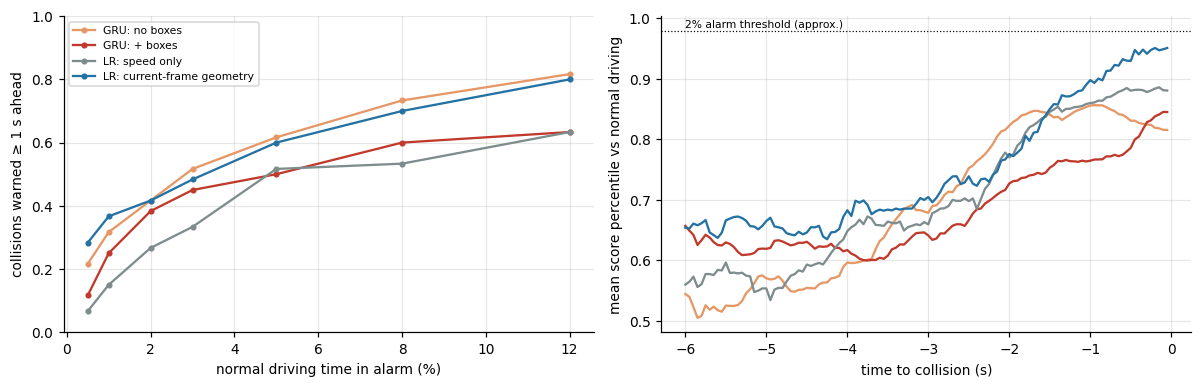

In [10]:
# left: warning rate vs alarm budget; right: average score in the 6 s before each collision
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
COL = {"GRU: + boxes": "#c0392b", "GRU: no boxes": "#e59866", "LR: current-frame geometry": "#2471a3",
       "LR: speed only": "#7f8c8d"}
neg = M["y"] == 0
for name, (score, _) in S.items():
    pts = []
    for b in [0.005, 0.01, 0.02, 0.03, 0.05, 0.08, 0.12]:
        a = fg.alarm_metrics(score, np.quantile(score[neg], 1 - b), M, EIDS)
        pts.append((100 * a["alarm_time"], a["recall_1s"]))
    pts = np.array(pts)
    axes[0].plot(pts[:, 0], pts[:, 1], marker="o", ms=3, color=COL[name], label=name)
axes[0].set_xlabel("normal driving time in alarm (%)"); axes[0].set_ylabel("collisions warned ≥ 1 s ahead")
axes[0].set_ylim(0, 1); axes[0].legend(fontsize=7)

row_of = {(r, s): i for i, (r, s) in enumerate(zip(M["route"], M["step"]))}
t_axis = np.arange(-120, 1) * ew.DT
for name, (score, _) in S.items():
    pct = np.searchsorted(np.sort(score[neg]), score) / neg.sum()      # score as percentile of normal driving
    trace = np.full((len(ev_index), len(t_axis)), np.nan)
    for j, e in enumerate(ev_index):
        for k, s in enumerate(range(e["step"] - 120, e["step"] + 1)):
            i = row_of.get((int(e["route"]), s))
            if i is not None:
                trace[j, k] = pct[i]
    axes[1].plot(t_axis, np.nanmean(trace, 0), color=COL[name], label=name)
axes[1].axhline(1 - BUDGET, color="k", ls=":", lw=0.8)
axes[1].text(-6, 1 - BUDGET + 0.005, "2% alarm threshold (approx.)", fontsize=7)
axes[1].set_xlabel("time to collision (s)"); axes[1].set_ylabel("mean score percentile vs normal driving")
plt.tight_layout(); plt.savefig(OUT / "evaluation.png", bbox_inches="tight"); plt.show()

## 5. Findings

Numbers are for the 60 collisions in Bench2Drive v2, at a 2% alarm budget, on test routes. Brackets are 95% route-bootstrap intervals.

1. **The boxes did not make the GRU better on test routes.** With boxes, the GRU warned 28% [19, 41] of collisions at least 1 s ahead, against 38% [26, 51] without boxes. AUPRC was almost identical (0.158 vs 0.152). None of the paired differences is clear: every interval includes 0.
2. **On validation the boxes looked clearly better, but that didn't carry over to test.** The box GRU had higher validation AUPRC in all 5 folds (0.27–0.65 vs 0.10–0.31), but the validation curves jump around from epoch to epoch. Each validation split holds only about 10 collisions, so early stopping picks a lucky epoch, and the extra 14 box features give the GRU more ways to overfit 48 training collisions.
3. **Plain logistic regression on the current box geometry is still as good as either GRU.** It warned 40% [28, 51] at ≥ 1 s, with the best AUPRC (0.199) and the longest median lead (0.78 s). So the useful box signal is mostly in the *current* geometry (clearance and time-to-collision on TF++'s planned path), and 3 s of history doesn't add anything a GRU can learn from this little data.
4. **Every learned monitor beats speed only, at least in ranking quality** (AUROC 0.69–0.74 vs 0.63). At this budget, though, the event-warning differences against speed only are within the noise.
5. **Early warning is hard for all of them.** At most ~20% of collisions get a warning ≥ 2 s ahead. The right-hand plot shows the scores only start to rise in the last ~2–3 s before impact, and on average they stay below the alarm threshold.

**What this means.** With about 60 collisions, a GRU can't reliably learn from the box features. More data (Longest6 v2 and more seeds) is the main lever, not a bigger model. Until then, the current-frame geometry monitor is the baseline to beat.

**Limits of this case study.** One random seed, no tuning, and a single validation split per fold, so treat the GRU numbers as rough (±10 points on recall is noise here). The LR rows pick thresholds with an inner 4-fold split; the GRU uses one 20% validation split.